In [1]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2

# Locate project root
root = Path.cwd()

if root.name == "notebooks":
    root = root.parent

# Read model forecasts
historical_df = pd.read_csv(
    root / "results" / "historical_var_es_forecasts.csv",
    parse_dates=["Date"]
)

parametric_df = pd.read_csv(
    root / "results" / "parametric_var_es_forecasts.csv",
    parse_dates=["Date"]
)

monte_carlo_df = pd.read_csv(
    root / "results" / "monte_carlo_var_es_forecasts.csv",
    parse_dates=["Date"]
)

models = {
    "Historical": historical_df,
    "Parametric": parametric_df,
    "Monte Carlo": monte_carlo_df
}

for name, model_df in models.items():
    print(
        f"{name}: {len(model_df)} observations, "
        f"{model_df['Date'].min().date()} to "
        f"{model_df['Date'].max().date()}"
    )


Historical: 3732 observations, 2011-12-28 to 2026-10-30
Parametric: 3732 observations, 2011-12-28 to 2026-10-30
Monte Carlo: 3732 observations, 2011-12-28 to 2026-10-30


In [2]:

# Step 3: Compare VaR Exception Rates

results = []

for model_name, model_df in models.items():

    actual_loss = -model_df["actual_return"]

    for confidence in [0.95, 0.99]:

        level = int(confidence * 100)

        var_column = f"var_{level}"

        # Identify VaR exceptions
        exceptions = actual_loss > model_df[var_column]

        n_forecasts = len(exceptions)
        n_exceptions = int(exceptions.sum())

        results.append({
            "Model": model_name,
            "Confidence": f"{level}%",
            "Observations": n_forecasts,
            "Exceptions": n_exceptions,
            "Expected Rate": 1 - confidence,
            "Observed Rate": n_exceptions / n_forecasts
        })

exception_summary = pd.DataFrame(results)

display(
    exception_summary.style.format({
        "Expected Rate": "{:.2%}",
        "Observed Rate": "{:.2%}"
    })
)


,Model,Confidence,Observations,Exceptions,Expected Rate,Observed Rate
0,Historical,95%,3732,176,5.00%,4.72%
1,Historical,99%,3732,50,1.00%,1.34%
2,Parametric,95%,3732,181,5.00%,4.85%
3,Parametric,99%,3732,83,1.00%,2.22%
4,Monte Carlo,95%,3732,181,5.00%,4.85%
5,Monte Carlo,99%,3732,85,1.00%,2.28%


In [3]:
# Step 4A: Kupiec POF Test

from scipy.stats import chi2
import numpy as np

def kupiec_test(n_exceptions, n_observations, confidence_level):

    # Expected exception probability
    p0 = 1 - confidence_level

    # Observed exception probability
    p_hat = n_exceptions / n_observations

    # Handle zero or all-exception cases safely
    if n_exceptions == 0:
        lr = -2 * n_observations * np.log1p(-p0)

    elif n_exceptions == n_observations:
        lr = -2 * n_observations * np.log(p0)

    else:
        lr = 2 * (
            n_exceptions * np.log(p_hat / p0)
            + (n_observations - n_exceptions)
            * np.log((1 - p_hat) / (1 - p0))
        )

    # Chi-square survival function
    p_value = chi2.sf(lr, df=1)

    return {
        "LR_POF": lr,
        "p_value": p_value,
        "reject_5pct": p_value < 0.05
    }

In [4]:
# Step 4B: Kupiec Test for all three models

kupiec_results = []

for _, row in exception_summary.iterrows():

    confidence = float(row["Confidence"].replace("%", "")) / 100

    result = kupiec_test(
        n_exceptions=int(row["Exceptions"]),
        n_observations=int(row["Observations"]),
        confidence_level=confidence
    )

    kupiec_results.append({
        "Model": row["Model"],
        "Confidence": row["Confidence"],
        "Exceptions": row["Exceptions"],
        "Observed Rate": row["Observed Rate"],
        "LR_POF": result["LR_POF"],
        "p_value": result["p_value"],
        "Reject H0 (5%)": result["reject_5pct"]
    })

kupiec_df = pd.DataFrame(kupiec_results)

display(
    kupiec_df.style.format({
        "Observed Rate": "{:.2%}",
        "LR_POF": "{:.4f}",
        "p_value": "{:.6g}"
    })
)

,Model,Confidence,Exceptions,Observed Rate,LR_POF,p_value,Reject H0 (5%)
0,Historical,95%,176,4.72%,0.6455,0.421711,False
1,Historical,99%,50,1.34%,3.9329,0.0473494,True
2,Parametric,95%,181,4.85%,0.1786,0.672573,False
3,Parametric,99%,83,2.22%,41.8928,9.64179e-11,True
4,Monte Carlo,95%,181,4.85%,0.1786,0.672573,False
5,Monte Carlo,99%,85,2.28%,45.1887,1.78935e-11,True


In [5]:

# Step 5A: Count Exception Transitions

def count_transitions(exceptions):

    # Convert True / False to 1 / 0
    exceptions = np.asarray(exceptions, dtype=int)

    # Previous-day and current-day states
    previous = exceptions[:-1]
    current = exceptions[1:]

    # Count four possible transitions
    n00 = np.sum((previous == 0) & (current == 0))
    n01 = np.sum((previous == 0) & (current == 1))
    n10 = np.sum((previous == 1) & (current == 0))
    n11 = np.sum((previous == 1) & (current == 1))

    return {
        "n00": int(n00),
        "n01": int(n01),
        "n10": int(n10),
        "n11": int(n11)
    }


In [6]:

# Step 5B: Transition Count Comparison

transition_results = []

for model_name, model_df in models.items():

    actual_loss = -model_df["actual_return"]

    for confidence in [0.95, 0.99]:

        level = int(confidence * 100)

        exceptions = (
            actual_loss > model_df[f"var_{level}"]
        )

        counts = count_transitions(exceptions)

        # Verify transition total
        assert sum(counts.values()) == len(exceptions) - 1

        transition_results.append({
            "Model": model_name,
            "Confidence": f"{level}%",
            **counts
        })

transition_df = pd.DataFrame(transition_results)

display(transition_df)


,Model,Confidence,n00,n01,n10,n11
0,Historical,95%,3401,155,154,21
1,Historical,99%,3637,44,44,6
2,Parametric,95%,3390,161,160,20
3,Parametric,99%,3576,72,72,11
4,Monte Carlo,95%,3390,161,160,20
5,Monte Carlo,99%,3572,74,74,11


In [7]:
# Step 5C: Conditional Exception Probabilities

transition_df["pi_01"] = (
    transition_df["n01"]
    / (transition_df["n00"] + transition_df["n01"])
)

transition_df["pi_11"] = (
    transition_df["n11"]
    / (transition_df["n10"] + transition_df["n11"])
)

display(
    transition_df.style.format({
        "pi_01": "{:.2%}",
        "pi_11": "{:.2%}"
    })
)

,Model,Confidence,n00,n01,n10,n11,pi_01,pi_11
0,Historical,95%,3401,155,154,21,4.36%,12.00%
1,Historical,99%,3637,44,44,6,1.20%,12.00%
2,Parametric,95%,3390,161,160,20,4.53%,11.11%
3,Parametric,99%,3576,72,72,11,1.97%,13.25%
4,Monte Carlo,95%,3390,161,160,20,4.53%,11.11%
5,Monte Carlo,99%,3572,74,74,11,2.03%,12.94%


In [8]:
from scipy.stats import chi2
from scipy.special import xlogy

def christoffersen_independence_test(n00, n01, n10, n11):

    # Conditional exception probabilities
    pi01 = n01 / (n00 + n01)
    pi11 = n11 / (n10 + n11)

    # Pooled exception probability
    pi = (n01 + n11) / (n00 + n01 + n10 + n11)

    # Log-likelihood under independence
    log_l0 = (
        xlogy(n00 + n10, 1 - pi)
        + xlogy(n01 + n11, pi)
    )

    # Log-likelihood under first-order Markov dependence
    log_l1 = (
        xlogy(n00, 1 - pi01)
        + xlogy(n01, pi01)
        + xlogy(n10, 1 - pi11)
        + xlogy(n11, pi11)
    )

    lr_ind = max(0.0, 2 * (log_l1 - log_l0))
    p_value = chi2.sf(lr_ind, df=1)

    return {
        "LR_IND": lr_ind,
        "p_value": p_value,
        "reject_5pct": p_value < 0.05
    }

In [9]:
independence_results = []

for _, row in transition_df.iterrows():

    result = christoffersen_independence_test(
        int(row["n00"]),
        int(row["n01"]),
        int(row["n10"]),
        int(row["n11"])
    )

    independence_results.append({
        "Model": row["Model"],
        "Confidence": row["Confidence"],
        "LR_IND": result["LR_IND"],
        "p_value": result["p_value"],
        "Reject H0 (5%)": result["reject_5pct"]
    })

independence_df = pd.DataFrame(independence_results)

display(
    independence_df.style.format({
        "LR_IND": "{:.4f}",
        "p_value": "{:.6g}"
    })
)

,Model,Confidence,LR_IND,p_value,Reject H0 (5%)
0,Historical,95%,15.7667,7.16529e-05,True
1,Historical,99%,16.8493,4.04677e-05,True
2,Parametric,95%,12.1622,0.000487687,True
3,Parametric,99%,23.1258,1.51743e-06,True
4,Monte Carlo,95%,12.1622,0.000487687,True
5,Monte Carlo,99%,22.1646,2.50244e-06,True


In [10]:
# Step 7A: Christoffersen Conditional Coverage Test

from scipy.stats import chi2

# Merge Kupiec and Independence results
cc_df = kupiec_df[
    ["Model", "Confidence", "LR_POF"]
].merge(
    independence_df[
        ["Model", "Confidence", "LR_IND"]
    ],
    on=["Model", "Confidence"],
    validate="one_to_one"
)

# Conditional Coverage LR statistic
cc_df["LR_CC"] = (
    cc_df["LR_POF"] + cc_df["LR_IND"]
)

# Chi-square p-value with 2 degrees of freedom
cc_df["p_value_CC"] = chi2.sf(
    cc_df["LR_CC"],
    df=2
)

# Reject null hypothesis at 5% significance
cc_df["Reject H0 (5%)"] = (
    cc_df["p_value_CC"] < 0.05
)

display(
    cc_df.style.format({
        "LR_POF": "{:.4f}",
        "LR_IND": "{:.4f}",
        "LR_CC": "{:.4f}",
        "p_value_CC": "{:.6g}"
    })
)

,Model,Confidence,LR_POF,LR_IND,LR_CC,p_value_CC,Reject H0 (5%)
0,Historical,95%,0.6455,15.7667,16.4122,0.000272979,True
1,Historical,99%,3.9329,16.8493,20.7823,3.07037e-05,True
2,Parametric,95%,0.1786,12.1622,12.3408,0.00209043,True
3,Parametric,99%,41.8928,23.1258,65.0186,7.61026e-15,True
4,Monte Carlo,95%,0.1786,12.1622,12.3408,0.00209043,True
5,Monte Carlo,99%,45.1887,22.1646,67.3533,2.36818e-15,True


In [11]:

# Step 8: Expected Shortfall Tail Diagnostics

es_results = []

for model_name, model_df in models.items():

    actual_loss = -model_df["actual_return"]

    for confidence in [0.95, 0.99]:

        level = int(confidence * 100)

        var_forecast = model_df[f"var_{level}"]
        es_forecast = model_df[f"es_{level}"]

        # Identify VaR exception days
        exceptions = actual_loss > var_forecast

        # Realized losses on exception days
        tail_losses = actual_loss[exceptions]

        # ES forecasts corresponding to exception days
        tail_es_forecasts = es_forecast[exceptions]

        # Tail diagnostics
        realized_tail_mean = tail_losses.mean()
        forecast_es_mean = tail_es_forecasts.mean()

        es_results.append({
            "Model": model_name,
            "Confidence": f"{level}%",
            "Tail Days": int(exceptions.sum()),
            "Realized Tail Loss": realized_tail_mean,
            "Forecast ES": forecast_es_mean,
            "Tail Difference": (
                realized_tail_mean - forecast_es_mean
            )
        })

es_diagnostics_df = pd.DataFrame(es_results)

display(
    es_diagnostics_df.style.format({
        "Realized Tail Loss": "{:.4%}",
        "Forecast ES": "{:.4%}",
        "Tail Difference": "{:.4%}"
    })
)


,Model,Confidence,Tail Days,Realized Tail Loss,Forecast ES,Tail Difference
0,Historical,95%,176,2.5393%,2.3969%,0.1424%
1,Historical,99%,50,3.7842%,3.5771%,0.2071%
2,Parametric,95%,181,2.4866%,1.9492%,0.5374%
3,Parametric,99%,83,3.1925%,2.4398%,0.7528%
4,Monte Carlo,95%,181,2.4866%,1.9489%,0.5377%
5,Monte Carlo,99%,85,3.1576%,2.4290%,0.7286%


In [12]:

# Step 9A: Joint VaR-ES Scoring (FZ0)

def joint_var_es_score(
    actual_loss, var_forecast, es_forecast, confidence_level
):
    loss = np.asarray(actual_loss, dtype=float)
    var = np.asarray(var_forecast, dtype=float)
    es = np.asarray(es_forecast, dtype=float)

    alpha = 1 - confidence_level

    if not 0 < confidence_level < 1:
        raise ValueError("Invalid confidence level.")

    if loss.shape != var.shape or loss.shape != es.shape:
        raise ValueError("Input shapes must match.")

    if not (
        np.isfinite(loss).all()
        and np.isfinite(var).all()
        and np.isfinite(es).all()
    ):
        raise ValueError("Inputs must be finite.")

    if np.any(es <= 0):
        raise ValueError("FZ0 requires strictly positive ES.")

    exceedance = (loss > var).astype(float)

    score = (
        var / es
        + np.log(es)
        - 1
        + exceedance * (loss - var) / (alpha * es)
    )

    return score


In [13]:
# Step 9B: Compare Joint VaR-ES Scores

score_results = []

for model_name, model_df in models.items():

    actual_loss = -model_df["actual_return"].to_numpy()

    for confidence in [0.95, 0.99]:

        level = int(confidence * 100)

        scores = joint_var_es_score(
            actual_loss=actual_loss,
            var_forecast=model_df[f"var_{level}"],
            es_forecast=model_df[f"es_{level}"],
            confidence_level=confidence
        )

        score_results.append({
            "Model": model_name,
            "Confidence": f"{level}%",
            "Mean FZ0 Score": scores.mean(),
            "Score Std": scores.std(ddof=1),
            "Observations": len(scores)
        })

fz_score_df = pd.DataFrame(score_results)

display(
    fz_score_df.sort_values(
        ["Confidence", "Mean FZ0 Score"]
    ).style.format({
        "Mean FZ0 Score": "{:.6f}",
        "Score Std": "{:.6f}"
    })
)

,Model,Confidence,Mean FZ0 Score,Score Std,Observations
0,Historical,95%,-3.620178,2.646071,3732
2,Parametric,95%,-3.572465,3.310901,3732
4,Monte Carlo,95%,-3.572331,3.309051,3732
1,Historical,99%,-3.045914,5.453462,3732
3,Parametric,99%,-2.756745,9.779116,3732
5,Monte Carlo,99%,-2.755703,9.775340,3732


In [14]:

# Step 10A: Build daily FZ0 score differences

daily_scores = []

for model_name, model_df in models.items():

    actual_loss = -model_df["actual_return"].to_numpy()

    for confidence in [0.95, 0.99]:

        level = int(confidence * 100)

        scores = joint_var_es_score(
            actual_loss=actual_loss,
            var_forecast=model_df[f"var_{level}"],
            es_forecast=model_df[f"es_{level}"],
            confidence_level=confidence
        )

        daily_scores.append(
            pd.DataFrame({
                "Date": model_df["Date"].to_numpy(),
                "Model": model_name,
                "Confidence": f"{level}%",
                "FZ0_Score": scores
            })
        )

daily_scores_df = pd.concat(
    daily_scores, ignore_index=True
)

score_wide = daily_scores_df.pivot(
    index=["Date", "Confidence"],
    columns="Model",
    values="FZ0_Score"
).sort_index()

assert len(score_wide) == 3732 * 2
assert not score_wide.isna().any().any()

display(score_wide.head())


Model                  Historical  Monte Carlo  Parametric
Date       Confidence                                     
2011-12-28 95%          -3.653675    -3.729477   -3.734797
           99%          -3.180670    -3.393028   -3.399037
2011-12-29 95%          -3.653675    -3.731771   -3.732453
           99%          -3.180670    -3.400821   -3.397054
2011-12-30 95%          -3.653675    -3.731862   -3.732876

In [16]:

import statsmodels.api as sm

def hac_score_difference_test(
    score_a, score_b, maxlags=10
):
    """
    Test E[Score_B - Score_A] = 0.

    Positive mean difference:
    Model A has a lower average FZ0 score.
    """

    a = np.asarray(score_a, dtype=float)
    b = np.asarray(score_b, dtype=float)

    if a.shape != b.shape or a.ndim != 1:
        raise ValueError("Scores must be aligned 1D arrays.")

    if not np.isfinite(a).all() or not np.isfinite(b).all():
        raise ValueError("Scores must be finite.")

    if len(a) <= maxlags:
        raise ValueError("Insufficient observations for HAC lags.")

    difference = b - a

    # Intercept-only regression estimates mean difference
    X = np.ones((len(difference), 1))

    fitted = sm.OLS(difference, X).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": maxlags}
    )

    return {
        "Mean Difference": float(fitted.params[0]),
        "HAC SE": float(fitted.bse[0]),
        "t-stat": float(fitted.tvalues[0]),
        "p-value": float(fitted.pvalues[0])
    }


In [17]:
# Step 10C: HAC comparison of joint VaR-ES scores

comparisons = [
    ("Historical", "Parametric"),
    ("Historical", "Monte Carlo"),
    ("Parametric", "Monte Carlo")
]

hac_results = []

for confidence in ["95%", "99%"]:

    current = score_wide.xs(
        confidence, level="Confidence"
    ).sort_index()

    for model_a, model_b in comparisons:

        result = hac_score_difference_test(
            score_a=current[model_a].to_numpy(),
            score_b=current[model_b].to_numpy(),
            maxlags=10
        )

        hac_results.append({
            "Confidence": confidence,
            "Model A": model_a,
            "Model B": model_b,
            **result,
            "Reject H0 (5%)": result["p-value"] < 0.05
        })

hac_df = pd.DataFrame(hac_results)

display(
    hac_df.style.format({
        "Mean Difference": "{:.6f}",
        "HAC SE": "{:.6f}",
        "t-stat": "{:.4f}",
        "p-value": "{:.6g}"
    })
)

,Confidence,Model A,Model B,Mean Difference,HAC SE,t-stat,p-value,Reject H0 (5%)
0,95%,Historical,Parametric,0.047713,0.019657,2.4273,0.0152127,True
1,95%,Historical,Monte Carlo,0.047847,0.019585,2.4430,0.0145667,True
2,95%,Parametric,Monte Carlo,0.000134,0.000405,0.3302,0.741278,False
3,99%,Historical,Parametric,0.289168,0.123787,2.3360,0.0194908,True
4,99%,Historical,Monte Carlo,0.290211,0.123763,2.3449,0.0190325,True
5,99%,Parametric,Monte Carlo,0.001042,0.001539,0.6773,0.498207,False


In [18]:

# Step 11A: HAC Lag Sensitivity Analysis

lag_choices = [5, 10, 20, 40]

sensitivity_results = []

for confidence in ["95%", "99%"]:

    current = score_wide.xs(
        confidence,
        level="Confidence"
    ).sort_index()

    for model_a, model_b in comparisons:

        for lag in lag_choices:

            result = hac_score_difference_test(
                score_a=current[model_a].to_numpy(),
                score_b=current[model_b].to_numpy(),
                maxlags=lag
            )

            sensitivity_results.append({
                "Confidence": confidence,
                "Model A": model_a,
                "Model B": model_b,
                "HAC Lags": lag,
                "Mean Difference": result["Mean Difference"],
                "HAC SE": result["HAC SE"],
                "t-stat": result["t-stat"],
                "p-value": result["p-value"],
                "Reject H0 (5%)": result["p-value"] < 0.05
            })

sensitivity_df = pd.DataFrame(sensitivity_results)

display(
    sensitivity_df.style.format({
        "Mean Difference": "{:.6f}",
        "HAC SE": "{:.6f}",
        "t-stat": "{:.4f}",
        "p-value": "{:.6g}"
    })
)


,Confidence,Model A,Model B,HAC Lags,Mean Difference,HAC SE,t-stat,p-value,Reject H0 (5%)
0,95%,Historical,Parametric,5,0.047713,0.016898,2.8236,0.00474814,True
1,95%,Historical,Parametric,10,0.047713,0.019657,2.4273,0.0152127,True
2,95%,Historical,Parametric,20,0.047713,0.022618,2.1095,0.0349017,True
3,95%,Historical,Parametric,40,0.047713,0.024580,1.9411,0.0522421,False
4,95%,Historical,Monte Carlo,5,0.047847,0.016841,2.8410,0.0044966,True
5,95%,Historical,Monte Carlo,10,0.047847,0.019585,2.4430,0.0145667,True
6,95%,Historical,Monte Carlo,20,0.047847,0.022529,2.1238,0.0336885,True
7,95%,Historical,Monte Carlo,40,0.047847,0.024505,1.9525,0.0508794,False
8,95%,Parametric,Monte Carlo,5,0.000134,0.000417,0.3203,0.748719,False
9,95%,Parametric,Monte Carlo,10,0.000134,0.000405,0.3302,0.741278,False


In [19]:
# Step 11B: HAC p-value comparison table

pvalue_pivot = sensitivity_df.pivot_table(
    index=["Confidence", "Model A", "Model B"],
    columns="HAC Lags",
    values="p-value"
)

display(
    pvalue_pivot.style.format("{:.4f}")
)

In [20]:

# Step 12A: Annual FZ0 Score Comparison

annual_scores = daily_scores_df.copy()

# Extract calendar year
annual_scores["Year"] = annual_scores["Date"].dt.year

# Calculate annual average FZ0 score
annual_summary = (
    annual_scores
    .groupby(["Year", "Confidence", "Model"])
    .agg(
        Mean_FZ0=("FZ0_Score", "mean"),
        Observations=("FZ0_Score", "size")
    )
    .reset_index()
)

# Compare models side by side
annual_pivot = annual_summary.pivot(
    index=["Year", "Confidence"],
    columns="Model",
    values="Mean_FZ0"
)

display(
    annual_pivot.style.format("{:.4f}")
)


In [21]:
# Step 12B: Annual Score Differences

annual_difference = annual_pivot.copy()

annual_difference["Parametric - Historical"] = (
    annual_difference["Parametric"]
    - annual_difference["Historical"]
)

annual_difference["Monte Carlo - Historical"] = (
    annual_difference["Monte Carlo"]
    - annual_difference["Historical"]
)

display(
    annual_difference[
        [
            "Parametric - Historical",
            "Monte Carlo - Historical"
        ]
    ].style.format("{:+.4f}")
)

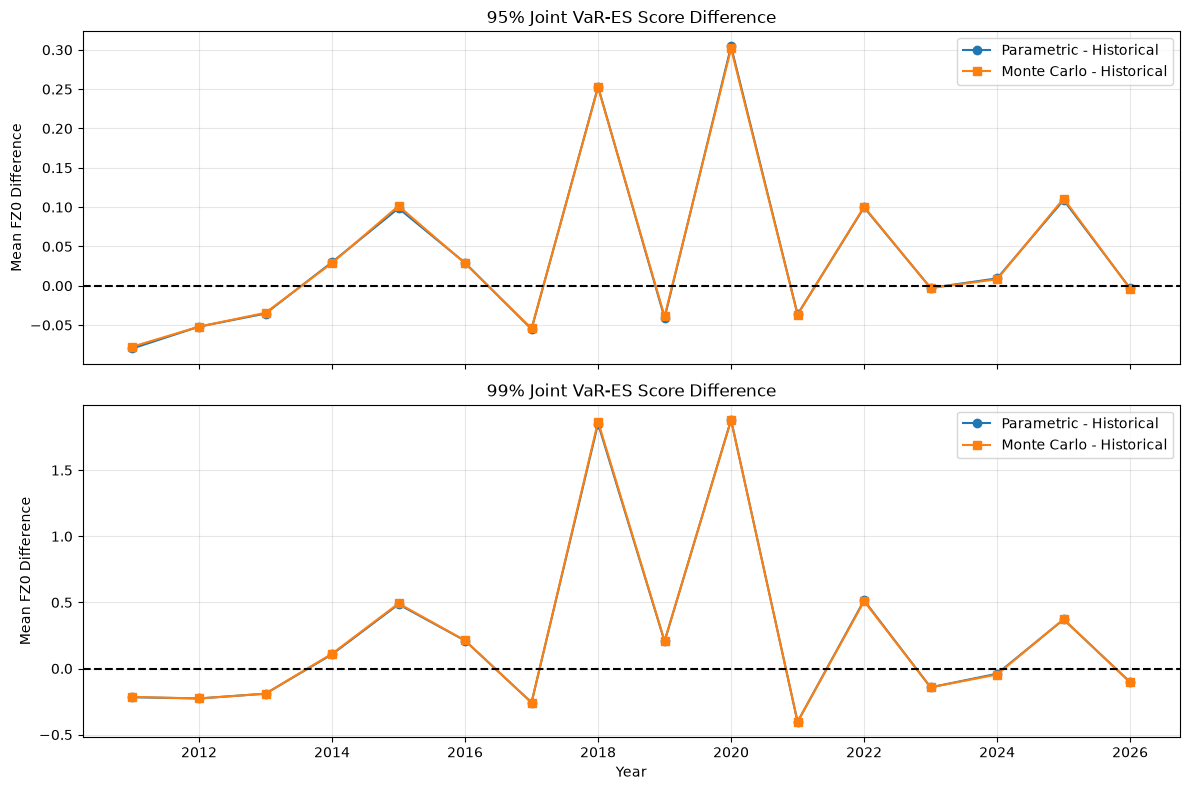

In [22]:
# Step 12C: Annual FZ0 Score Difference Plot

fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 8),
    sharex=True
)

for ax, confidence in zip(axes, ["95%", "99%"]):

    current = annual_difference.xs(
        confidence,
        level="Confidence"
    )

    ax.plot(
        current.index,
        current["Parametric - Historical"],
        marker="o",
        label="Parametric - Historical"
    )

    ax.plot(
        current.index,
        current["Monte Carlo - Historical"],
        marker="s",
        label="Monte Carlo - Historical"
    )

    ax.axhline(0, color="black", linestyle="--")

    ax.set_title(f"{confidence} Joint VaR-ES Score Difference")
    ax.set_ylabel("Mean FZ0 Difference")
    ax.legend()
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Year")

plt.tight_layout()
plt.show()

In [23]:

# Step 13A: Leave-One-Year-Out Analysis

loyo_results = []

for confidence in ["95%", "99%"]:

    current = score_wide.xs(
        confidence,
        level="Confidence"
    ).sort_index().copy()

    current["Year"] = current.index.year

    for model_b in ["Parametric", "Monte Carlo"]:

        current["Difference"] = (
            current[model_b] - current["Historical"]
        )

        full_mean = current["Difference"].mean()

        for excluded_year in sorted(current["Year"].unique()):

            remaining = current.loc[
                current["Year"] != excluded_year,
                "Difference"
            ]

            new_mean = remaining.mean()

            loyo_results.append({
                "Confidence": confidence,
                "Comparison": f"{model_b} - Historical",
                "Excluded Year": excluded_year,
                "Remaining Days": len(remaining),
                "Full Mean Difference": full_mean,
                "LOYO Mean Difference": new_mean,
                "Change": new_mean - full_mean
            })

loyo_df = pd.DataFrame(loyo_results)

display(
    loyo_df.style.format({
        "Full Mean Difference": "{:+.4f}",
        "LOYO Mean Difference": "{:+.4f}",
        "Change": "{:+.4f}"
    })
)


,Confidence,Comparison,Excluded Year,Remaining Days,Full Mean Difference,LOYO Mean Difference,Change
0,95%,Parametric - Historical,2011,3729,+0.0477,+0.0478,+0.0001
1,95%,Parametric - Historical,2012,3482,+0.0477,+0.0549,+0.0072
2,95%,Parametric - Historical,2013,3480,+0.0477,+0.0537,+0.0060
3,95%,Parametric - Historical,2014,3480,+0.0477,+0.0490,+0.0013
4,95%,Parametric - Historical,2015,3480,+0.0477,+0.0440,-0.0037
5,95%,Parametric - Historical,2016,3480,+0.0477,+0.0491,+0.0013
6,95%,Parametric - Historical,2017,3481,+0.0477,+0.0551,+0.0074
7,95%,Parametric - Historical,2018,3481,+0.0477,+0.0329,-0.0148
8,95%,Parametric - Historical,2019,3480,+0.0477,+0.0541,+0.0064
9,95%,Parametric - Historical,2020,3479,+0.0477,+0.0291,-0.0187


In [24]:
# Step 13B: Exclude 2018 and 2020 together

exclusion_results = []

for confidence in ["95%", "99%"]:

    current = score_wide.xs(
        confidence,
        level="Confidence"
    ).sort_index()

    years = current.index.year

    for model_b in ["Parametric", "Monte Carlo"]:

        difference = (
            current[model_b] - current["Historical"]
        )

        scenarios = {
            "Full Sample": np.ones(len(current), dtype=bool),
            "Exclude 2018": years != 2018,
            "Exclude 2020": years != 2020,
            "Exclude Both": ~np.isin(years, [2018, 2020])
        }

        for scenario, mask in scenarios.items():

            remaining = difference[mask]

            exclusion_results.append({
                "Confidence": confidence,
                "Comparison": f"{model_b} - Historical",
                "Scenario": scenario,
                "Observations": len(remaining),
                "Mean Difference": remaining.mean()
            })

exclusion_df = pd.DataFrame(exclusion_results)

display(
    exclusion_df.pivot_table(
        index=["Confidence", "Comparison"],
        columns="Scenario",
        values="Mean Difference"
    ).style.format("{:+.4f}")
)

In [25]:

# Step 14A: HAC Tests Excluding 2018 and 2020

robustness_results = []

for confidence in ["95%", "99%"]:

    current = score_wide.xs(
        confidence,
        level="Confidence"
    ).sort_index()

    years = current.index.year

    scenarios = {
        "Full Sample": np.ones(len(current), dtype=bool),
        "Exclude Both": ~np.isin(years, [2018, 2020])
    }

    for scenario, mask in scenarios.items():

        subset = current.loc[mask]

        for model_b in ["Parametric", "Monte Carlo"]:

            for lag in [10, 40]:

                result = hac_score_difference_test(
                    score_a=subset["Historical"].to_numpy(),
                    score_b=subset[model_b].to_numpy(),
                    maxlags=lag
                )

                robustness_results.append({
                    "Confidence": confidence,
                    "Scenario": scenario,
                    "Comparison": f"{model_b} - Historical",
                    "HAC Lags": lag,
                    "Observations": len(subset),
                    "Mean Difference": result["Mean Difference"],
                    "p-value": result["p-value"],
                    "Reject H0 (5%)": result["p-value"] < 0.05
                })

robustness_df = pd.DataFrame(robustness_results)

display(
    robustness_df.style.format({
        "Mean Difference": "{:+.6f}",
        "p-value": "{:.6g}"
    })
)


,Confidence,Scenario,Comparison,HAC Lags,Observations,Mean Difference,p-value,Reject H0 (5%)
0,95%,Full Sample,Parametric - Historical,10,3732,+0.047713,0.0152127,True
1,95%,Full Sample,Parametric - Historical,40,3732,+0.047713,0.0522421,False
2,95%,Full Sample,Monte Carlo - Historical,10,3732,+0.047847,0.0145667,True
3,95%,Full Sample,Monte Carlo - Historical,40,3732,+0.047847,0.0508794,False
4,95%,Exclude Both,Parametric - Historical,10,3228,+0.011628,0.297947,False
5,95%,Exclude Both,Parametric - Historical,40,3228,+0.011628,0.368492,False
6,95%,Exclude Both,Monte Carlo - Historical,10,3228,+0.012058,0.282977,False
7,95%,Exclude Both,Monte Carlo - Historical,40,3228,+0.012058,0.353961,False
8,99%,Full Sample,Parametric - Historical,10,3732,+0.289168,0.0194908,True
9,99%,Full Sample,Parametric - Historical,40,3732,+0.289168,0.0603524,False


In [26]:
pvalue_robustness = robustness_df.pivot_table(
    index=["Confidence", "Comparison", "Scenario"],
    columns="HAC Lags",
    values="p-value"
)

display(
    pvalue_robustness.style.format("{:.6f}")
)

In [27]:

# Step 15A: Holm Multiple Testing Correction

from statsmodels.stats.multitest import multipletests

# Use original HAC lag=10 comparison results
holm_df = hac_df.copy()

reject, p_adjusted, _, _ = multipletests(
    holm_df["p-value"].to_numpy(),
    alpha=0.05,
    method="holm"
)

holm_df["Holm Adjusted p-value"] = p_adjusted
holm_df["Reject After Holm (5%)"] = reject

display(
    holm_df[
        [
            "Confidence",
            "Model A",
            "Model B",
            "Mean Difference",
            "p-value",
            "Holm Adjusted p-value",
            "Reject After Holm (5%)"
        ]
    ].style.format({
        "Mean Difference": "{:+.6f}",
        "p-value": "{:.6f}",
        "Holm Adjusted p-value": "{:.6f}"
    })
)


,Confidence,Model A,Model B,Mean Difference,p-value,Holm Adjusted p-value,Reject After Holm (5%)
0,95%,Historical,Parametric,+0.047713,0.015213,0.087400,False
1,95%,Historical,Monte Carlo,+0.047847,0.014567,0.087400,False
2,95%,Parametric,Monte Carlo,+0.000134,0.741278,0.996415,False
3,99%,Historical,Parametric,+0.289168,0.019491,0.087400,False
4,99%,Historical,Monte Carlo,+0.290211,0.019033,0.087400,False
5,99%,Parametric,Monte Carlo,+0.001042,0.498207,0.996415,False
